# Flight ticket prices: how much do models really add?

**Goal:** predict the price of a flight ticket and find out how much a model adds over very simple rules, and how well it works for flights it has **never seen**.

**Data:** *Flight Price Prediction* (Kaggle, Shubham Bathwal): **300,153 bookings** scraped from EaseMyTrip between February 11 and March 31, 2022, for flights among India's six largest cities. For each booking: airline, flight code, source and destination city, departure and arrival time slot, number of stops, class (Economy or Business), duration, days left until departure and the price in Indian rupees. Put `Clean_Dataset.csv` in a `data/` folder next to this notebook.

**Two traps this notebook is designed around:** a large share of the price is explained by one variable (the class), so a high R-squared is easy; and the same flights appear again and again, so *how* the data is split decides how good the model looks.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder

sns.set_theme(style="whitegrid")
SEED = 42
df = pd.read_csv("data/Clean_Dataset.csv")

## 1. The data

In [2]:
print("Rows, columns:", df.shape, "| missing values:", int(df.isna().sum().sum()), "| duplicated rows:", int(df.duplicated().sum()))
print(f"Different flight codes: {df.flight.nunique():,} | rows per flight code (min / median / max): {df.groupby('flight').size().agg(['min', 'median', 'max']).astype(int).tolist()}")
print("Days left until departure:", df.days_left.min(), "to", df.days_left.max())
display(df.groupby("class").price.describe()[["count", "min", "50%", "mean", "max"]].round(0).astype(int))

Rows, columns: (300153, 11) | missing values: 0 | duplicated rows: 0
Different flight codes: 1,561 | rows per flight code (min / median / max): [1, 55, 3235]
Days left until departure: 1 to 49


,count,min,50%,mean,max
class,,,,,
Business,93487,12000,53164,52540,123071
Economy,206666,1105,5772,6572,42349


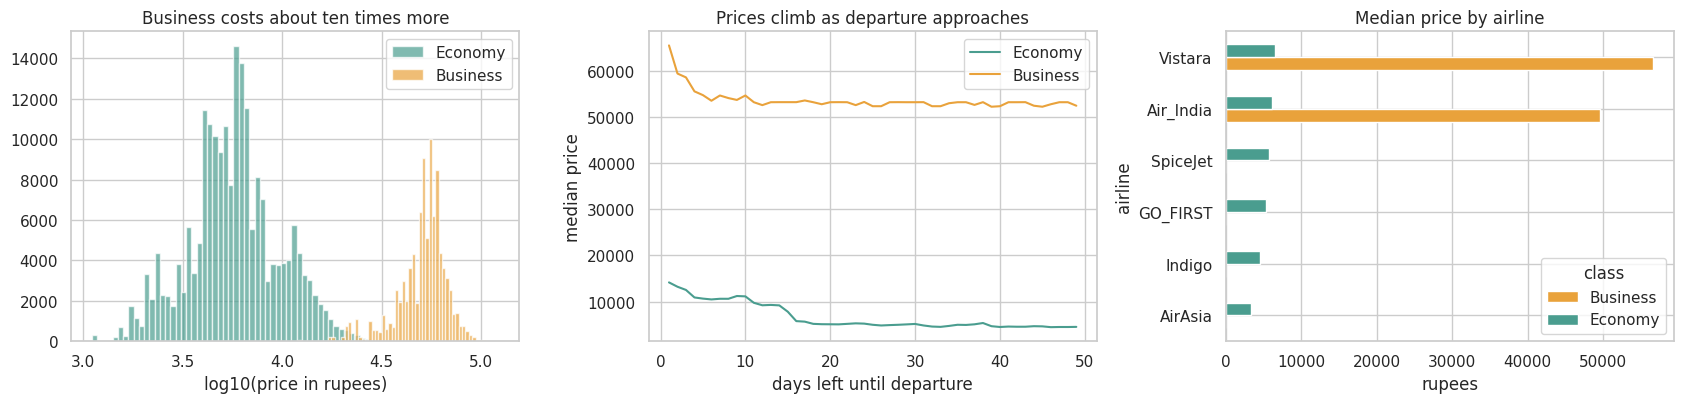

Airlines offering Business class: ['Air_India', 'Vistara']


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for cls, color in (("Economy", "#4a9d8f"), ("Business", "#e9a23b")):
    axes[0].hist(np.log10(df[df["class"] == cls].price), bins=60, alpha=.7, label=cls, color=color)
axes[0].set_xlabel("log10(price in rupees)"); axes[0].set_title("Business costs about ten times more"); axes[0].legend()
for cls, color in (("Economy", "#4a9d8f"), ("Business", "#e9a23b")):
    m = df[df["class"] == cls].groupby("days_left").price.median(); axes[1].plot(m.index, m.values, color=color, label=cls)
axes[1].set_xlabel("days left until departure"); axes[1].set_ylabel("median price"); axes[1].set_title("Prices climb as departure approaches"); axes[1].legend()
ac = df.groupby(["airline", "class"]).price.median().unstack().sort_values("Economy"); ac.plot.barh(ax=axes[2], color=["#e9a23b", "#4a9d8f"]); axes[2].set_title("Median price by airline"); axes[2].set_xlabel("rupees")
plt.tight_layout(); plt.show()
print("Airlines offering Business class:", sorted(df[df["class"] == "Business"].airline.unique()))

## 2. What does a trivial model already explain?

Before any model, two **lookup tables** built on the training data: the average price of each class, and the average price of each combination of class, airline, route and number of stops. Any model has to beat these to be worth anything.

In [4]:
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED)
tr, te = df.iloc[train_idx], df.iloc[test_idx]

def lookup(keys):
    means = tr.groupby(keys).price.mean()
    return te[keys].merge(means.rename("p"), left_on=keys, right_index=True, how="left").p.fillna(tr.price.mean()).values

def scores(y, pred, cls):
    eco = (cls == "Economy").values
    return {"R2": r2_score(y, pred), "MAE (rupees)": mean_absolute_error(y, pred),
            "MAE economy": mean_absolute_error(y[eco], pred[eco]), "MAE business": mean_absolute_error(y[~eco], pred[~eco]),
            "R2 inside economy": r2_score(y[eco], pred[eco]), "R2 inside business": r2_score(y[~eco], pred[~eco])}

y_te = te.price.values
base = pd.DataFrame({
    "only the class's average price":                         scores(y_te, lookup(["class"]), te["class"]),
    "average of class + airline + route + stops":             scores(y_te, lookup(["class", "airline", "source_city", "destination_city", "stops"]), te["class"]),
}).T
display(base.round(3))

,R2,MAE (rupees),MAE economy,MAE business,R2 inside economy,R2 inside business
only the class's average price,0.880,4876.135,2704.077,9671.257,-0.000,-0.000
average of class + airline + route + stops,0.947,3329.730,2330.037,5536.693,0.263,0.612


**The class alone gives an R-squared of 0.88**, because Business costs roughly nine times more than Economy. That is why R-squared is a poor yardstick here: it is high for almost any model. The numbers that matter are the **error in rupees** and the **R-squared inside each class** (how much of the variation *among* Economy tickets, or among Business tickets, the model explains).

## 3. Two ways of splitting the data

- **Random split (80/20):** every flight code appears on both sides. The model is judged on flights it has already seen on other days.
- **Split by flight code (80/20):** the test flights are **never seen** in training. This is the honest test for "a flight the model has no history for".

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
g_train, g_test = next(gss.split(df, groups=df.flight))
print(f"Random split : train {len(train_idx):,} / test {len(test_idx):,} rows")
print(f"By flight    : train {len(g_train):,} / test {len(g_test):,} rows | flight codes in both sets: {len(set(df.flight.iloc[g_train]) & set(df.flight.iloc[g_test]))}")

Random split : train 240,122 / test 60,031 rows
By flight    : train 244,465 / test 55,688 rows | flight codes in both sets: 0


## 4. Models, fitted on the training side only

Everything that learns from data (encoders, scalers, models) is **fitted on the training rows and only applied to the test rows**.

- *First-version style (B, C):* each category replaced by its average price, then min-max scaling, then linear regression; the flight code was encoded and then dropped for being collinear with the airline. Shown with the encoder and scaler fitted on **all** the data (as in the first version) and on the **training data only**.
- *A variant that keeps the flight code (D, E):* not in the first version; it shows what the same shortcut does to a high-cardinality identifier (1,561 flight codes), fitted on all the data and on the training data only.
- *Linear regression* with one-hot categories (F) and *gradient boosting* (G), both without the flight code.

In [6]:
CAT = ["airline", "source_city", "departure_time", "stops", "arrival_time", "destination_city", "class"]
NUM = ["duration", "days_left"]
CAT_WITH_FLIGHT = CAT + ["flight"]

def first_version(train_rows, test_rows, fit_on_all, keep_flight=False):
    # mean-price encoding of every category + min-max scaling + linear regression
    # (the first version dropped the encoded flight code afterwards, for being collinear with the airline)
    ref = df if fit_on_all else df.iloc[train_rows]
    gm = ref.price.mean()
    cols = CAT_WITH_FLIGHT if keep_flight else CAT
    enc = {c: ref.groupby(c).price.mean() for c in cols}
    X = pd.DataFrame({c: df[c].map(enc[c]).fillna(gm) for c in cols}); X[NUM] = df[NUM]
    sc = MinMaxScaler().fit(X if fit_on_all else X.iloc[train_rows])
    X = pd.DataFrame(sc.transform(X), columns=X.columns)
    return LinearRegression().fit(X.iloc[train_rows], df.price.iloc[train_rows]).predict(X.iloc[test_rows])

def linear_onehot(train_rows, test_rows):
    pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), CAT), ("n", "passthrough", NUM)])
    return Pipeline([("p", pre), ("m", LinearRegression())]).fit(df.iloc[train_rows], df.price.iloc[train_rows]).predict(df.iloc[test_rows])

def boosting(train_rows, test_rows):
    enc = OrdinalEncoder(categories=[sorted(df[c].unique()) for c in CAT])            # only the list of categories, no statistics
    pre = ColumnTransformer([("c", enc, CAT), ("n", "passthrough", NUM)])
    mask = [True] * len(CAT) + [False] * len(NUM)
    model = HistGradientBoostingRegressor(categorical_features=mask, max_iter=300, random_state=SEED)
    return Pipeline([("p", pre), ("m", model)]).fit(df.iloc[train_rows], df.price.iloc[train_rows]).predict(df.iloc[test_rows])

def lookup_pred(train_rows, test_rows, keys):
    tr_, te_ = df.iloc[train_rows], df.iloc[test_rows]
    means = tr_.groupby(keys).price.mean()
    return te_[keys].merge(means.rename("p"), left_on=keys, right_index=True, how="left").p.fillna(tr_.price.mean()).values

KEYS = ["class", "airline", "source_city", "destination_city", "stops"]
rows = {}
for split_name, (a, b) in {"random split": (train_idx, test_idx), "unseen flights": (g_train, g_test)}.items():
    y, cls = df.price.iloc[b].values, df["class"].iloc[b]
    runs = {
        "A. average of class + airline + route + stops":     lookup_pred(a, b, KEYS),
        "B. first version (encoder+scaler on ALL data)":      first_version(a, b, fit_on_all=True),
        "C. first version, fitted on TRAIN only":             first_version(a, b, fit_on_all=False),
        "D. variant keeping flight code, ALL data":           first_version(a, b, fit_on_all=True, keep_flight=True),
        "E. variant keeping flight code, TRAIN only":         first_version(a, b, fit_on_all=False, keep_flight=True),
        "F. linear regression, one-hot":                      linear_onehot(a, b),
        "G. gradient boosting":                               boosting(a, b),
    }
    for name, pred in runs.items():
        rows[(split_name, name)] = scores(y, pred, cls)
res = pd.DataFrame(rows).T
display(res.round(3))

R2  \
random split   A. average of class + airline + route + stops  0.947   
               B. first version (encoder+scaler on ALL data)  0.902   
               C. first version, fitted on TRAIN only         0.902   
               D. variant keeping flight code, ALL data       0.906   
               E. variant keeping flight code, TRAIN only     0.906   
               F. linear regression, one-hot                  0.911   
               G. gradient boosting                           0.977   
unseen flights A. average of class + airline + route + stops  0.935   
               B. first version (encoder+scaler on ALL data)  0.905   
               C. first version, fitted on TRAIN only         0.904   
               D. variant keeping flight code, ALL data       0.909   
               E. variant keeping flight code, TRAIN only     0.887   
               F. linear regression, one-hot                  0.908   
               G. gradient boosting                           0.958   

                                                              MAE (rupees)  \
random split   A. average of class + airline + route + stops      3329.730   
               B. first version (encoder+scaler on ALL data)      4632.951   
               C. first version, fitted on TRAIN only             4632.165   
               D. variant keeping flight code, ALL data           4621.945   
               E. variant keeping flight code, TRAIN only         4622.893   
               F. linear regression, one-hot                      4553.290   
               G. gradient boosting                               1981.424   
unseen flights A. average of class + airline + route + stops      3645.035   
               B. first version (encoder+scaler on ALL data)      4524.730   
               C. first version, fitted on TRAIN only             4516.047   
               D. variant keeping flight code, ALL data           4495.676   
               E. variant keeping flight code, TRAIN only         5231.734   
               F. linear regression, one-hot                      4650.826   
               G. gradient boosting                               2659.695   

                                                              MAE economy  \
random split   A. average of class + airline + route + stops     2330.037   
               B. first version (encoder+scaler on ALL data)     2715.379   
               C. first version, fitted on TRAIN only            2715.152   
               D. variant keeping flight code, ALL data          2873.818   
               E. variant keeping flight code, TRAIN only        2874.344   
               F. linear regression, one-hot                     2883.138   
               G. gradient boosting                              1166.620   
unseen flights A. average of class + airline + route + stops     2501.819   
               B. first version (encoder+scaler on ALL data)     2689.639   
               C. first version, fitted on TRAIN only            2658.345   
               D. variant keeping flight code, ALL data          2853.896   
               E. variant keeping flight code, TRAIN only        3453.052   
               F. linear regression, one-hot                     2983.132   
               G. gradient boosting                              1272.149   

                                                              MAE business  \
random split   A. average of class + airline + route + stops      5536.693   
               B. first version (encoder+scaler on ALL data)      8866.261   
               C. first version, fitted on TRAIN only             8864.240   
               D. variant keeping flight code, ALL data           8481.182   
               E. variant keeping flight code, TRAIN only         8483.062   
               F. linear regression, one-hot                      8240.387   
               G. gradient boosting                               3780.220   
unseen flights A. average of class + airline + r

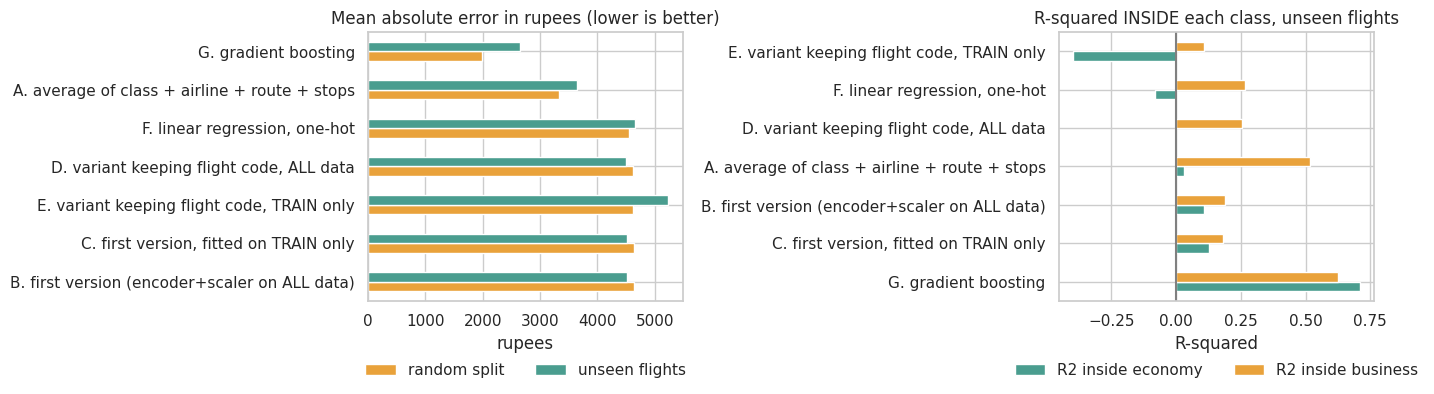

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
mae = res["MAE (rupees)"].unstack(0)
mae.sort_values("random split", ascending=False).plot.barh(ax=axes[0], color=["#e9a23b", "#4a9d8f"]); axes[0].set_title("Mean absolute error in rupees (lower is better)"); axes[0].set_xlabel("rupees")
r2in = res[["R2 inside economy", "R2 inside business"]].xs("unseen flights"); r2in.sort_values("R2 inside economy", ascending=False).plot.barh(ax=axes[1], color=["#4a9d8f", "#e9a23b"])
axes[1].axvline(0, color="grey"); axes[1].set_title("R-squared INSIDE each class, unseen flights"); axes[1].set_xlabel("R-squared")
for ax in axes: ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

## 5. What drives the price?

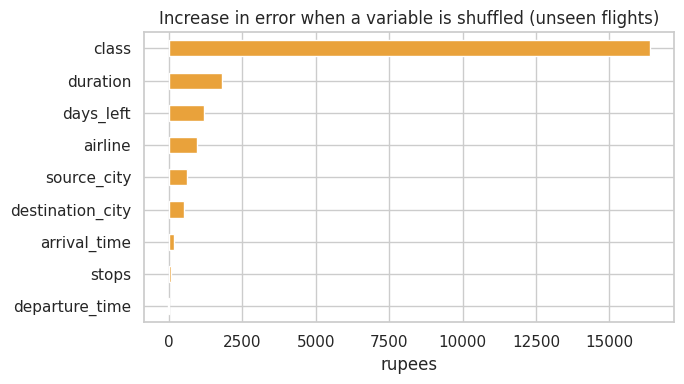

Increase in mean absolute error (rupees) when each variable is shuffled:
class               16382
duration             1809
days_left            1199
airline               957
source_city           618
destination_city      530
arrival_time          183
stops                  83
departure_time        -17


In [8]:
enc = OrdinalEncoder(categories=[sorted(df[c].unique()) for c in CAT]); pre = ColumnTransformer([("c", enc, CAT), ("n", "passthrough", NUM)])
model = Pipeline([("p", pre), ("m", HistGradientBoostingRegressor(categorical_features=[True] * len(CAT) + [False] * len(NUM), max_iter=300, random_state=SEED))])
model.fit(df.iloc[g_train], df.price.iloc[g_train])
sample = df.iloc[g_test].sample(20000, random_state=SEED)
imp = permutation_importance(model, sample[CAT + NUM], sample.price, scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=CAT + NUM).sort_values()
importance.plot.barh(figsize=(7, 4), color="#e9a23b"); plt.title("Increase in error when a variable is shuffled (unseen flights)"); plt.xlabel("rupees"); plt.tight_layout(); plt.show()
print("Increase in mean absolute error (rupees) when each variable is shuffled:"); print(importance.sort_values(ascending=False).round(0).astype(int).to_string())

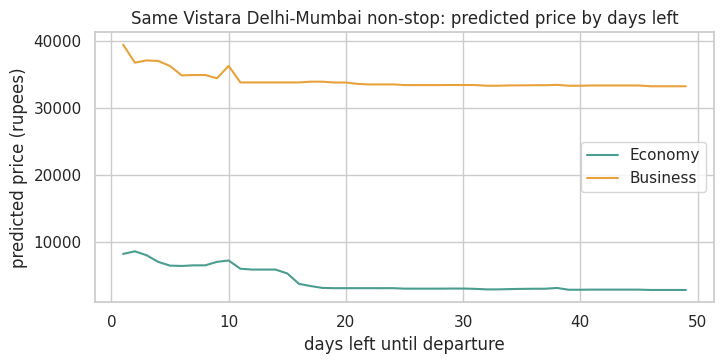

Economy, predicted price 1 / 3 / 7 / 21 / 49 days before departure: [8261, 8065, 6558, 3150, 2880]


In [9]:
# what the model says about days left, for the same ticket: price at 1 .. 49 days before departure
ref = df[(df.airline == "Vistara") & (df.source_city == "Delhi") & (df.destination_city == "Mumbai") & (df.stops == "zero")].iloc[[0]].copy()
curves = {}
for cls in ("Economy", "Business"):
    grid = pd.concat([ref.assign(**{"class": cls, "days_left": d}) for d in range(1, 50)], ignore_index=True)
    curves[cls] = pd.Series(model.predict(grid[CAT + NUM]), index=range(1, 50))
fig, ax = plt.subplots(figsize=(7.4, 3.8))
for cls, color in (("Economy", "#4a9d8f"), ("Business", "#e9a23b")):
    ax.plot(curves[cls].index, curves[cls].values, color=color, label=cls)
ax.set_xlabel("days left until departure"); ax.set_ylabel("predicted price (rupees)"); ax.set_title("Same Vistara Delhi-Mumbai non-stop: predicted price by days left"); ax.legend()
plt.tight_layout(); plt.show()
print("Economy, predicted price 1 / 3 / 7 / 21 / 49 days before departure:", [int(curves["Economy"][d]) for d in (1, 3, 7, 21, 49)])

## 6. Conclusions

- **The class explains most of the price.** Business costs about nine times more than Economy, so the class alone gives an R-squared of 0.88. R-squared is high for almost any model here; the error in rupees and the R-squared *inside* each class are what tell models apart.
- **The linear models add little.** With an R-squared of about 0.90 to 0.91 they are **worse than a lookup table** of class + airline + route + stops (mean error 4,550 to 4,630 rupees against 3,330 under a random split) and explain little of the variation inside a class (R-squared inside Economy: 0.13 for the first version, 0.03 for the one-hot model).
- **A non-linear model does add value.** Gradient boosting cuts the error by about **40%** against the lookup table for flights it has seen (1,981 against 3,330 rupees) and by about **27%** for flights it has never seen (2,660 against 3,645).
- **A random split flatters the model.** For new flights the error is 34% higher overall (1,981 to 2,660) and 56% higher in Business (3,780 to 5,891 rupees). Judging by a random split answers "do I know this flight?", not "can I price a new one?".
- **Fitting the encoder on all the data**, as the first version did, hardly mattered there (error 4,633 against 4,632 rupees under a random split, 4,525 against 4,516 for unseen flights), because the flight code was dropped and the other seven categories have few values. The same shortcut **is dangerous for a high-cardinality identifier**: had the flight code been kept, fitting the encoder on all the data would have reported an error of 4,496 rupees against 5,232 for unseen flights (R-squared inside Economy -0.005 against -0.397).
- **What drives the price:** the class by far (shuffling it adds 16,382 rupees of error), then the duration (1,809), the days left (1,199) and the airline (957); the cities matter a little (about 500 to 600) and the departure time and the stops hardly at all. For the same Economy ticket the model predicts about 8,300 rupees one day before departure and about 2,900 rupees 49 days before, flat after roughly three weeks.

**Limitations**

- One scrape of 50 days from one website (February and March 2022), with no trip dates: the model cannot be tested over time or on seasonality and holidays.
- These are asking prices on the day of the scrape, not what travellers paid.
- Business class is offered only by Air India and Vistara.
- Splitting by flight code tests new flight codes, but the routes, airlines and schedules still repeat; a new route or another market would be harder.
- The boosting model was not tuned.

**Next steps:** tune the model, predict intervals instead of single values, and, if dates become available, evaluate on later periods.